<a href="https://colab.research.google.com/github/saara-19-hub/databricks-hub/blob/main/CNN_Minor_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
from google.colab import files

In [3]:
uploaded = files.upload()

Saving kidney_disease.csv to kidney_disease.csv


In [4]:
file_name = next(iter(uploaded))

In [5]:
df = pd.read_csv("/content/kidney_disease.csv")

In [6]:
print("First 5 rows of the dataset")
display(df.head())

First 5 rows of the dataset


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (400, 26)


In [8]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


In [9]:
print("\nData types")
print(df.dtypes)


Data types
id                  int64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv                object
wc                 object
rc                 object
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object


In [10]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
id                  0
age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64


In [11]:
print("\nClassification labels:")
print(df["classification"].value_counts(dropna=False))


Classification labels:
classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


## Load the data

In [12]:
import pandas as pd
import numpy as np

In [13]:
df.columns = df.columns.str.strip()

In [14]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace("?", np.nan)

In [15]:
print("Duplicat rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

Duplicat rows: 0


In [16]:
df["classification"] = df["classification"].str.lower()
df = df.dropna(subset=["classification"]).copy()
df = df[df["classification"].isin(["ckd", "notckd"])].copy()

print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["classification"].value_counts())


Dataset shape: (400, 26)

Class distribution:
classification
ckd       250
notckd    150
Name: count, dtype: int64


In [17]:
numeric_cols = [
     "age", "bp", "sg", "al", "su", "bgr", "bu",
    "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"
]
for col in numeric_cols:
  df[col] = pd.to_numeric(df[col], errors="coerce")
print("Numerical columns converted.")
print("\nMissing values per column:")
print(df.isnull().sum())

Numerical columns converted.

Missing values per column:
id                  0
age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                71
wc                106
rc                131
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import  Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [19]:
X = df.drop(columns=["classification"])
y = df["classification"].map({"noted": 0, "ckd": 1})

In [20]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

In [21]:
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

In [22]:
df['classification'] = (
    df['classification']
    .astype('string')
    .str.strip()
    .str.lower()
)

In [23]:
df['classification'] = df['classification'].replace({
    'ckd\t': 'ckd',
    'not ckd': 'notckd'
})

In [24]:
df = df[
    df['classification'].isin(['ckd', 'notckd'])
].copy()

In [25]:
X = df.drop(columns=['classification', 'id'],errors='ignore')
y = df['classification'].map({
    'notckd': 0,
    'ckd': 1
})

In [26]:
print("Missing target values:", y.isna().sum())
print("Class distribution:")
print(y.value_counts())

Missing target values: 0
Class distribution:
classification
1    250
0    150
Name: count, dtype: int64


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [28]:
print("Training data:", X_train.shape)
print("Training data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (320, 24)
Training data: (80, 24)
Training labels: (320,)
Testing labels: (80,)


## Build and Train the CNN Model

In [29]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [30]:
numeric_cols = [
    "age", "bp", "sg", "al", "su", "bgr", "bu",
    "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"
]

numeric_features = [col for col in numeric_cols if col in X_train.columns]
categorical_features = [
    col for col in X_train.columns if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

print("Preprocessing completed successfully!")
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)


Preprocessing completed successfully!
Training data shape: (320, 34)
Testing data shape: (80, 34)


In [31]:
X_train_cnn = X_train_processed[..., None]
X_test_cnn = X_test_processed[..., None]

y_train_cnn = y_train.to_numpy(dtype=np.float32)
y_test_cnn = y_test.to_numpy(dtype=np.float32)

In [32]:
print("CNN training shape:", X_train_cnn.shape)
print("CNN training shape:", X_test_cnn.shape)
print("CNN input preparation completed!")

CNN training shape: (320, 34, 1)
CNN training shape: (80, 34, 1)
CNN input preparation completed!


In [33]:

model = Sequential([
    Input(shape=(X_train_cnn.shape[1], 1)),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(32, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 34, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 34, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,449 (33.00 KB)

 Trainable params: 8,449 (33.00 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [35]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_cnn,
    y_train_cnn,
    epochs=50,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6133 - loss: 0.6676 - val_accuracy: 0.6406 - val_loss: 0.6489
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6211 - loss: 0.6452 - val_accuracy: 0.6406 - val_loss: 0.6381
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6211 - loss: 0.6324 - val_accuracy: 0.6406 - val_loss: 0.6266
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6250 - loss: 0.6239 - val_accuracy: 0.6406 - val_loss: 0.6085
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6250 - loss: 0.6027 - val_accuracy: 0.6406 - val_loss: 0.5869
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6680 - loss: 0.5767 - val_accuracy: 0.6406 - val_loss: 0.5622
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6641 - loss: 0.5424 - val_accuracy: 0.8438 - val_loss: 0.5391
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7188 - loss: 0.5160 - val_accuracy: 0.8281 - val_loss

## Training Graphs

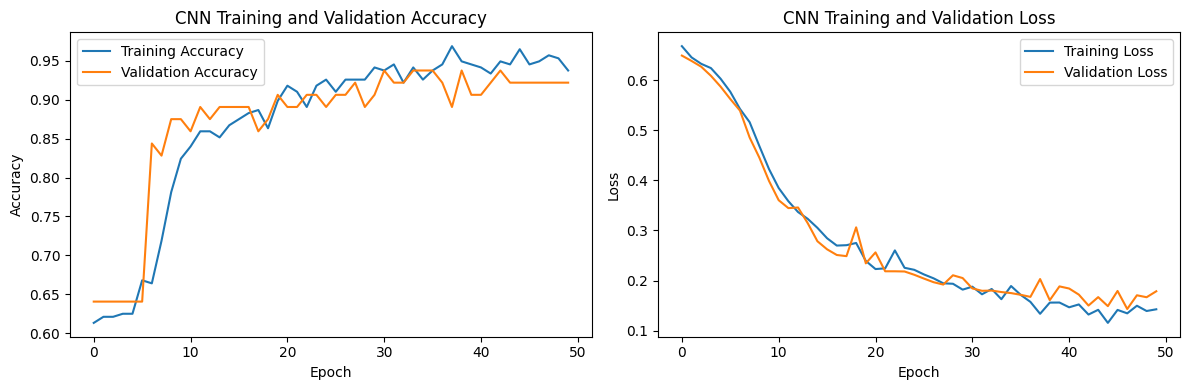

In [36]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [37]:
test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test_cnn,
    verbose=0
)
print("===== CNN MODEL EVALUATION =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

===== CNN MODEL EVALUATION =====
Test Loss: 0.1220
Test Accuracy: 93.75%


## Confusion Matrix

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

     Not CKD       0.93      0.90      0.92        30
         CKD       0.94      0.96      0.95        50

    accuracy                           0.94        80
   macro avg       0.94      0.93      0.93        80
weighted avg       0.94      0.94      0.94        80



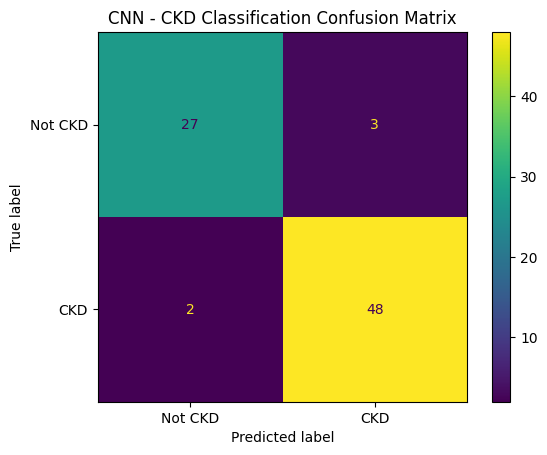

ROC-AUC: 0.992


In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt
import numpy as np
probabilities = model.predict(X_test_cnn, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)
y_true = y_test_cnn.astype(int)
print("===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    predictions,
    labels=[0, 1],
    target_names=["Not CKD", "CKD"],
    zero_division=0
))
cm = confusion_matrix(y_true, predictions, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not CKD", "CKD"]
)
disp.plot()
plt.title("CNN - CKD Classification Confusion Matrix")
plt.show()
if len(np.unique(y_true)) == 2:
  print(
      "ROC-AUC:",
      round(roc_auc_score(y_true, probabilities), 4)
  )

In [42]:
plt.savefig(
    "CKD_CNN_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
print("Confusion matrix saved!")

Confusion matrix saved!


<Figure size 640x480 with 0 Axes>

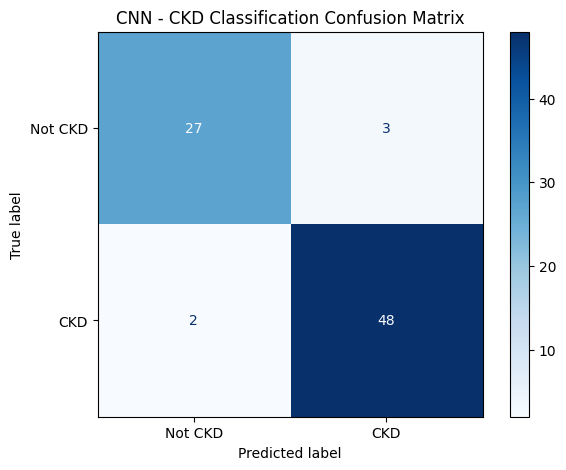

Confusion matrix saved successfully!


In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not CKD", "CKD"]
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("CNN - CKD Classification Confusion Matrix")

fig.savefig(
    "/content/CKD_CNN_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Confusion matrix saved successfully!")


In [44]:
from google.colab import files

files.download("/content/CKD_CNN_Confusion_Matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Saved the trained CNN Model

In [45]:
model.save("/content/CKD_CNN_Model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


In [46]:
import joblib

joblib.dump(
    preprocessor,
    "/content/CKD_Preprocessing_Pipeline.pkl"
)

print("Preprocessing pipeline saved successfully!")

Preprocessing pipeline saved successfully!


In [47]:
from google.colab import files

files.download("/content/CKD_CNN_Model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
files.download("/content/CKD_Preprocessing_Pipeline.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

import tensorflow as tf
import joblib

loaded_model = tf.keras.models.load_model(
    "/content/CKD_CNN_Model.keras"
)

loaded_preprocessor = joblib.load(
    "/content/CKD_Preprocessing_Pipeline.pkl"
)

print("CNN model loaded successfully!")
print("Preprocessing pipeline loaded successfully!")


CNN model loaded successfully!
Preprocessing pipeline loaded successfully!


In [50]:

# Select one test record
sample = X_test.iloc[[0]]

# Apply the saved preprocessing pipeline
sample_processed = loaded_preprocessor.transform(sample)

# Reshape for the CNN
sample_cnn = sample_processed[..., None]

# Predict probability
probability = loaded_model.predict(
    sample_cnn, verbose=0
)[0][0]

predicted_class = "CKD" if probability >= 0.5 else "Not CKD"

print("Predicted class:", predicted_class)
print(f"Model score for CKD: {probability:.4f}")


Predicted class: Not CKD
Model score for CKD: 0.0248
